# 1. Load Manhattan NTA boundaries

In [35]:
import geopandas as gpd
from pathlib import Path

RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")

nta = gpd.read_file(RAW / "nynta2020.shp")
nta.head()

,BoroCode,BoroName,CountyFIPS,NTA2020,NTAName,NTAAbbrev,NTAType,CDTA2020,CDTAName,Shape_Leng,Shape_Area,geometry
0,3,Brooklyn,047,BK0101,Greenpoint,Grnpt,0,BK01,BK01 Williamsburg-Greenpoint (CD 1 Equivalent),28919.560728,3.532181e+07,"POLYGON ((1003059.997 204572.025, 1002991.367 ..."
1,3,Brooklyn,047,BK0102,Williamsburg,Wllmsbrg,0,BK01,BK01 Williamsburg-Greenpoint (CD 1 Equivalent),28134.082737,2.885285e+07,"POLYGON ((995851.916 203199.332, 995969.193 20..."
2,3,Brooklyn,047,BK0103,South Williamsburg,SWllmsbrg,0,BK01,BK01 Williamsburg-Greenpoint (CD 1 Equivalent),18250.280091,1.520896e+07,"POLYGON ((998047.21 196303.325, 998157.901 196..."
3,3,Brooklyn,047,BK0104,East Williamsburg,EWllmsbrg,0,BK01,BK01 Williamsburg-Greenpoint (CD 1 Equivalent),43184.800376,5.226741e+07,"POLYGON ((1005302.497 199455.73, 1005307.792 1..."
4,3,Brooklyn,047,BK0201,Brooklyn Heights,BkHts,0,BK02,BK02 Downtown Brooklyn-Fort Greene (CD 2 Appro...,14312.192285,9.982023e+06,"POLYGON ((986367.736 190549.239, 985813.836 19..."


In [5]:
nta_manhattan = nta[nta["BoroName"] == "Manhattan"].copy()
print("Manhattan NTAs:", len(nta_manhattan))
nta_manhattan[["NTA2020", "NTAName"]].head(10)

Manhattan NTAs: 38


,NTA2020,NTAName
118,MN0101,Financial District-Battery Park City
119,MN0102,Tribeca-Civic Center
120,MN0191,The Battery-Governors Island-Ellis Island-Libe...
121,MN0201,SoHo-Little Italy-Hudson Square
122,MN0202,Greenwich Village
123,MN0203,West Village
124,MN0301,Chinatown-Two Bridges
125,MN0302,Lower East Side
126,MN0303,East Village
127,MN0401,Chelsea-Hudson Yards


In [6]:
print("CRS:", nta_manhattan.crs)

CRS: EPSG:2263


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

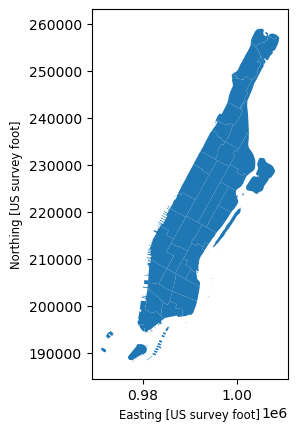

In [7]:
nta_manhattan.plot()

# 2. Load ACS household income data

In [17]:
import os

for f in os.listdir(RAW):
    print(f)

ACSDT5Y2024.B19025-Data.csv
ACSDT5Y2024.B11001-Table-Notes.txt
acs_household.csv
nynta2020.dbf
nynta2020.shx
nynta2020.shp
ACSDT5Y2024.B19025-Table-Notes.txt
acs_income.csv
nynta2020.prj
ACSDT5Y2024.B11001-Data.csv
nynta2020.shp.xml


In [18]:
import pandas as pd

income = pd.read_csv(RAW / "ACSDT5Y2024.B19025-Data.csv")
households = pd.read_csv(RAW / "ACSDT5Y2024.B11001-Data.csv")

print("Income shape:", income.shape)
print("Households shape:", households.shape)

Income shape: (85385, 5)
Households shape: (85385, 21)


/var/folders/3z/t6vlbnwj4wv5m60f80yjjjxw0000gn/T/ipykernel_61416/2816256146.py:4: DtypeWarning: Columns (2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19) have mixed types. Specify dtype option on import or set low_memory=False.
  households = pd.read_csv(RAW / "ACSDT5Y2024.B11001-Data.csv")


In [19]:
print("Income columns:")
print(income.columns.tolist())

print("\nHousehold columns:")
print(households.columns.tolist())

Income columns:
['GEO_ID', 'NAME', 'B19025_001E', 'B19025_001M', 'Unnamed: 4']

Household columns:
['GEO_ID', 'NAME', 'B11001_001E', 'B11001_001M', 'B11001_002E', 'B11001_002M', 'B11001_003E', 'B11001_003M', 'B11001_004E', 'B11001_004M', 'B11001_005E', 'B11001_005M', 'B11001_006E', 'B11001_006M', 'B11001_007E', 'B11001_007M', 'B11001_008E', 'B11001_008M', 'B11001_009E', 'B11001_009M', 'Unnamed: 20']


In [20]:
households.head()

,GEO_ID,NAME,B11001_001E,B11001_001M,B11001_002E,B11001_002M,B11001_003E,B11001_003M,B11001_004E,B11001_004M,...,B11001_005M,B11001_006E,B11001_006M,B11001_007E,B11001_007M,B11001_008E,B11001_008M,B11001_009E,B11001_009M,Unnamed: 20
0,Geography,Geographic Area Name,Estimate!!Total:,Margin of Error!!Total:,Estimate!!Total:!!Family households:,Margin of Error!!Total:!!Family households:,Estimate!!Total:!!Family households:!!Married-...,Margin of Error!!Total:!!Family households:!!M...,Estimate!!Total:!!Family households:!!Other fa...,Margin of Error!!Total:!!Family households:!!O...,...,Margin of Error!!Total:!!Family households:!!O...,Estimate!!Total:!!Family households:!!Other fa...,Margin of Error!!Total:!!Family households:!!O...,Estimate!!Total:!!Nonfamily households:,Margin of Error!!Total:!!Nonfamily households:,Estimate!!Total:!!Nonfamily households:!!House...,Margin of Error!!Total:!!Nonfamily households:...,Estimate!!Total:!!Nonfamily households:!!House...,Margin of Error!!Total:!!Nonfamily households:...,NaN
1,0400000US36,New York,7722646,12717,4738075,13456,3279487,15988,1458588,9559,...,5898,1060419,8193,2984571,12394,2398170,12430,586401,7149,NaN
2,0500000US36061,"New York County, New York",778281,4924,320699,4352,214047,3855,106652,3051,...,1848,82122,2535,457582,5503,369128,5037,88454,2669,NaN
3,1400000US01001020100,Census Tract 201; Autauga County; Alabama,736,137,521,134,399,139,122,51,...,32,82,45,215,68,174,55,41,47,NaN
4,1400000US01001020200,Census Tract 202; Autauga County; Alabama,592,114,402,100,160,54,242,96,...,58,171,83,190,64,188,65,2,5,NaN


In [21]:
income.head()


,GEO_ID,NAME,B19025_001E,B19025_001M,Unnamed: 4
0,Geography,Geographic Area Name,Estimate!!Aggregate household income in the pa...,Margin of Error!!Aggregate household income in...,NaN
1,0400000US36,New York,990409253700,5271114011,NaN
2,0500000US36061,"New York County, New York",151076814100,2372140897,NaN
3,1400000US01001020100,Census Tract 201; Autauga County; Alabama,59209600,13040834,NaN
4,1400000US01001020200,Census Tract 202; Autauga County; Alabama,49983400,11500157,NaN


In [22]:
income = pd.read_csv(
    RAW / "ACSDT5Y2024.B19025-Data.csv",
    skiprows=[1]
)

households = pd.read_csv(
    RAW / "ACSDT5Y2024.B11001-Data.csv",
    skiprows=[1]
)

In [23]:
income.head()
households.head()

,GEO_ID,NAME,B11001_001E,B11001_001M,B11001_002E,B11001_002M,B11001_003E,B11001_003M,B11001_004E,B11001_004M,...,B11001_005M,B11001_006E,B11001_006M,B11001_007E,B11001_007M,B11001_008E,B11001_008M,B11001_009E,B11001_009M,Unnamed: 20
0,0400000US36,New York,7722646,12717,4738075,13456,3279487,15988,1458588,9559,...,5898,1060419,8193,2984571,12394,2398170,12430,586401,7149,NaN
1,0500000US36061,"New York County, New York",778281,4924,320699,4352,214047,3855,106652,3051,...,1848,82122,2535,457582,5503,369128,5037,88454,2669,NaN
2,1400000US01001020100,Census Tract 201; Autauga County; Alabama,736,137,521,134,399,139,122,51,...,32,82,45,215,68,174,55,41,47,NaN
3,1400000US01001020200,Census Tract 202; Autauga County; Alabama,592,114,402,100,160,54,242,96,...,58,171,83,190,64,188,65,2,5,NaN
4,1400000US01001020300,Census Tract 203; Autauga County; Alabama,1235,169,821,170,545,155,276,134,...,31,251,131,414,99,371,101,43,50,NaN


In [24]:
# Keeping only Manhattan census tracts
income = income[
    income["GEO_ID"].str.startswith("1400000US36061", na=False)
].copy()

households = households[
    households["GEO_ID"].str.startswith("1400000US36061", na=False)
].copy()

print("Income tract rows:", len(income))
print("Household tract rows:", len(households))

Income tract rows: 310
Household tract rows: 310


In [25]:
# We only need these columns
income = income[
    ["GEO_ID", "NAME", "B19025_001E"]
].copy()
households = households[
    ["GEO_ID", "NAME", "B11001_001E"]
].copy()

In [26]:
income = income.rename(columns={
    "B19025_001E": "aggregate_household_income"
})

households = households.rename(columns={
    "B11001_001E": "total_households"
})

In [27]:
income["aggregate_household_income"] = pd.to_numeric(
    income["aggregate_household_income"],
    errors="coerce"
)

households["total_households"] = pd.to_numeric(
    households["total_households"],
    errors="coerce"
)

In [28]:
# Both tables have the same GEO_ID so we combine them
acs = income.merge(
    households[["GEO_ID", "total_households"]],
    on="GEO_ID",
    how="inner"
)

acs.head()

,GEO_ID,NAME,aggregate_household_income,total_households
0,1400000US36061000100,Census Tract 1; New York County; New York,NaN,0
1,1400000US36061000201,Census Tract 2.01; New York County; New York,41625500.0,852
2,1400000US36061000202,Census Tract 2.02; New York County; New York,220922500.0,3163
3,1400000US36061000500,Census Tract 5; New York County; New York,NaN,0
4,1400000US36061000600,Census Tract 6; New York County; New York,344101000.0,5393


In [29]:
print("Final Manhattan ACS tract rows:", len(acs))
print("Missing income:", acs["aggregate_household_income"].isna().sum())
print("Missing households:", acs["total_households"].isna().sum())

acs.head()

Final Manhattan ACS tract rows: 310
Missing income: 9
Missing households: 0


,GEO_ID,NAME,aggregate_household_income,total_households
0,1400000US36061000100,Census Tract 1; New York County; New York,NaN,0
1,1400000US36061000201,Census Tract 2.01; New York County; New York,41625500.0,852
2,1400000US36061000202,Census Tract 2.02; New York County; New York,220922500.0,3163
3,1400000US36061000500,Census Tract 5; New York County; New York,NaN,0
4,1400000US36061000600,Census Tract 6; New York County; New York,344101000.0,5393


In [30]:
acs.loc[
    acs["aggregate_household_income"].isna(),
    ["GEO_ID", "NAME", "aggregate_household_income", "total_households"]
]

,GEO_ID,NAME,aggregate_household_income,total_households
0,1400000US36061000100,Census Tract 1; New York County; New York,NaN,0
3,1400000US36061000500,Census Tract 5; New York County; New York,NaN,0
87,1400000US36061008602,Census Tract 86.02; New York County; New York,NaN,0
158,1400000US36061014300,Census Tract 143; New York County; New York,NaN,0
244,1400000US36061021703,Census Tract 217.03; New York County; New York,NaN,0
271,1400000US36061024000,Census Tract 240; New York County; New York,NaN,0
301,1400000US36061029700,Census Tract 297; New York County; New York,NaN,0
306,1400000US36061031100,Census Tract 311; New York County; New York,NaN,0
309,1400000US36061031900,Census Tract 319; New York County; New York,NaN,0


In [32]:
acs["tract_geoid"] = acs["GEO_ID"].str.replace("1400000US", "", regex=False)
acs[["GEO_ID", "tract_geoid", "NAME"]].head()
# tract_geoid will be what we use to connect the ACS table to actual census tract geometry

,GEO_ID,tract_geoid,NAME
0,1400000US36061000100,36061000100,Census Tract 1; New York County; New York
1,1400000US36061000201,36061000201,Census Tract 2.01; New York County; New York
2,1400000US36061000202,36061000202,Census Tract 2.02; New York County; New York
3,1400000US36061000500,36061000500,Census Tract 5; New York County; New York
4,1400000US36061000600,36061000600,Census Tract 6; New York County; New York


In [33]:
# Remove tracts with no households
acs_clean = acs[
    (acs["total_households"] > 0) &
    (acs["aggregate_household_income"].notna())
].copy()

print("Rows before cleaning:", len(acs))
print("Rows after cleaning:", len(acs_clean))
print("Rows removed:", len(acs) - len(acs_clean))

Rows before cleaning: 310
Rows after cleaning: 301
Rows removed: 9


In [36]:
acs_clean.to_csv(
    PROCESSED / "manhattan_acs_income_by_tract.csv",
    index=False
)